In [18]:
import gluonts
from gluonts.dataset.repository import get_dataset, dataset_recipes
from gluonts.dataset.multivariate_grouper import MultivariateGrouper
from gluonts.dataset.repository.datasets import dataset_recipes, get_dataset
from gluonts.evaluation.backtest import make_evaluation_predictions
from gluonts.evaluation import MultivariateEvaluator
from matplotlib import pyplot as plt
import matplotlib.dates as mdates
from typing import List, Optional, Callable, Iterable
from itertools import islice
import pandas as pd
import numpy as np

In [5]:
print(f"Available datasets: {list(dataset_recipes.keys())}")


Available datasets: ['constant', 'exchange_rate', 'solar-energy', 'electricity', 'traffic', 'exchange_rate_nips', 'electricity_nips', 'traffic_nips', 'solar_nips', 'wiki2000_nips', 'wiki-rolling_nips', 'taxi_30min', 'kaggle_web_traffic_with_missing', 'kaggle_web_traffic_without_missing', 'kaggle_web_traffic_weekly', 'm1_yearly', 'm1_quarterly', 'm1_monthly', 'nn5_daily_with_missing', 'nn5_daily_without_missing', 'nn5_weekly', 'tourism_monthly', 'tourism_quarterly', 'tourism_yearly', 'cif_2016', 'london_smart_meters_without_missing', 'wind_farms_without_missing', 'car_parts_without_missing', 'dominick', 'fred_md', 'pedestrian_counts', 'hospital', 'covid_deaths', 'kdd_cup_2018_without_missing', 'weather', 'm3_monthly', 'm3_quarterly', 'm3_yearly', 'm3_other', 'm4_hourly', 'm4_daily', 'm4_weekly', 'm4_monthly', 'm4_quarterly', 'm4_yearly', 'm5', 'uber_tlc_daily', 'uber_tlc_hourly', 'airpassengers', 'australian_electricity_demand', 'electricity_hourly', 'electricity_weekly', 'rideshare_wit

In [19]:
dataset = get_dataset("electricity_nips", regenerate=False)
print(dataset.metadata)


freq='h' target=None feat_static_cat=[CategoricalFeatureInfo(name='feat_static_cat_0', cardinality='370')] feat_static_real=[] feat_dynamic_real=[] feat_dynamic_cat=[] prediction_length=24


In [20]:
dataset.train

Map(fn=<gluonts.dataset.common.ProcessDataEntry object at 0x7f8f0473da30>, iterable=JsonLinesFile(path=PosixPath('/home/artiintel/ahmelg/.gluonts/datasets/electricity_nips/train/data.json.gz'), start=0, n=None, line_starts=[0, 101020, 207498, 312548, 418789, 525363, 632738, 736977, 840691, 947488, 1047948, 1154524, 1255989, 1357151, 1464641, 1568369, 1671517, 1778489, 1878091, 1982810, 2089513, 2194735, 2295201, 2337230, 2441296, 2546481, 2651066, 2736649, 2839140, 2945864, 3053011, 3160654, 3267107, 3369224, 3469040, 3575163, 3679202, 3726652, 3815574, 3922022, 4024627, 4043883, 4146990, 4251236, 4356956, 4462686, 4561117, 4668402, 4775216, 4882689, 4989644, 5082884, 5190283, 5294649, 5401705, 5505725, 5611999, 5719143, 5824478, 5931254, 6038631, 6142545, 6249896, 6355418, 6460988, 6568403, 6673432, 6780605, 6887014, 6993127, 7095826, 7203469, 7307195, 7410599, 7518605, 7625404, 7732334, 7838854, 7945977, 8051493, 8150900, 8257989, 8363145, 8471096, 8575987, 8685786, 8793476, 8900161,

In [21]:
train_grouper = MultivariateGrouper(max_target_dim=min(2000, int(dataset.metadata.feat_static_cat[0].cardinality)))

test_grouper = MultivariateGrouper(num_test_dates=int(len(dataset.test)/len(dataset.train)), 
                                   max_target_dim=min(2000, int(dataset.metadata.feat_static_cat[0].cardinality)))

In [22]:
dataset_train = train_grouper(dataset.train)
dataset_test = test_grouper(dataset.test)


In [23]:
print(dataset_train[0].keys())
print(dataset_train[0]['target'].shape)

dict_keys(['target', 'start', 'feat_static_cat'])
(370, 5833)


In [9]:
print(f"Number of training samples: {len(dataset_test)}")

Number of training samples: 7


In [24]:
def create_date_embeddings(start_date_str, n_timepoints):
    # Convert string to datetime if needed
    if isinstance(start_date_str, str):
        start_date = pd.to_datetime(start_date_str)
    else:
        start_date = start_date_str
    
    # Create array of sequential timestamps - using hours now
    timestamps = [start_date + pd.Timedelta(hours=i) 
                 for i in range(n_timepoints)]
    
    # Initialize arrays for each feature
    hour_sin = np.zeros(n_timepoints)
    hour_cos = np.zeros(n_timepoints)
    day_sin = np.zeros(n_timepoints)
    day_cos = np.zeros(n_timepoints)
    month_sin = np.zeros(n_timepoints)
    month_cos = np.zeros(n_timepoints)
    
    # Fill arrays with embeddings for each timestamp
    for i, ts in enumerate(timestamps):
        hour_sin[i] = np.sin(2 * np.pi * ts.hour / 24.0)
        hour_cos[i] = np.cos(2 * np.pi * ts.hour / 24.0)
        day_sin[i] = np.sin(2 * np.pi * ts.dayofweek / 7.0)
        day_cos[i] = np.cos(2 * np.pi * ts.dayofweek / 7.0)
        month_sin[i] = np.sin(2 * np.pi * (ts.month - 1) / 12.0)
        month_cos[i] = np.cos(2 * np.pi * (ts.month - 1) / 12.0)
    
    # Stack all features
    return np.stack([hour_sin, hour_cos, day_sin, day_cos, month_sin, month_cos])


def add_temporal_covariates(dataset: Iterable[dict]) -> Iterable[dict]:
    for item in dataset:
        n_timepoints = item['target'].shape[1]
        date_covariates = create_date_embeddings(item['start'], n_timepoints)
        item['time_feat'] = date_covariates
    
    return dataset

In [110]:
dataset_train = add_temporal_covariates(dataset_train)
dataset_test = add_temporal_covariates(dataset_test)

print(dataset_train[0].keys())
print(dataset_train[0]['target'].shape)

dict_keys(['target', 'start', 'feat_static_cat', 'time_feat'])
(370, 5833)


In [26]:
date_formater = mdates.DateFormatter("%h")

entry = next(islice(dataset_train, 2))
entry.keys()
entry["start"]

Period('2014-01-01 00:00', 'h')

In [27]:
dataset_train[0]['target'].shape

(370, 5833)

NameError: name 'date_formater' is not defined

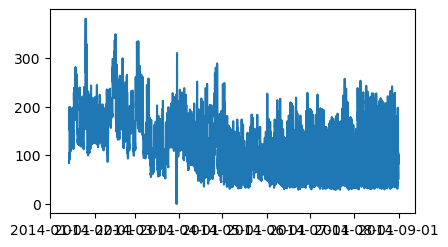

In [17]:
fig = plt.figure(figsize=(16, 9))
for idx, entry in enumerate(islice(dataset.train, 9)):
    ax = plt.subplot(3, 3, idx + 1)
    t = pd.date_range(
        start=entry["start"].to_timestamp(),
        periods=len(entry["target"]),
        freq=entry["start"].freq,
    )
    plt.plot(t, entry["target"])
    plt.xticks(pd.date_range(start="2014-01-01 00:00", periods=9, freq="1MS"))
    ax.xaxis.set_major_formatter(date_formater)

In [21]:
entry["target"].shape, entry["start"], entry["feat_static_cat"]

((5833,), Period('2014-01-01 00:00', 'h'), array([8], dtype=int32))

In [28]:
from gluonts.dataset.field_names import FieldName
from gluonts.transform import (
    AddObservedValuesIndicator,
    InstanceSplitter,
    ExpectedNumInstanceSampler,
    TestSplitSampler,
    Transformation,
    Chain,
    InstanceSampler,
    SelectFields,
)

from gluonts.dataset.loader import TrainDataLoader, InferenceDataLoader, ValidationDataLoader
from gluonts.itertools import Cached


In [154]:
from gluonts.transform import  SimpleTransformation,ValidationSplitSampler 
import numpy as np

class NumpyMeanScaler(SimpleTransformation):
    """
    GluonTS transform that implements mean scaling using numpy.
    """
    def __init__(
        self,
        dim=-1,
        keepdim=False,
        default_scale=None,
        minimum_scale=1e-10,
        field_name="target",
        ):
        self.dim = dim
        self.keepdim = keepdim
        self.default_scale = default_scale
        self.minimum_scale = minimum_scale
        self.field_name = field_name
        
    def transform(self, data: dict) -> dict:
        # Get the target data
        target = data[self.field_name]
        
        # Create observed indicator (assuming no missing values, modify if needed)
        observed_indicator = np.ones_like(target)
        
        # Compute scale factors
        ts_sum = np.sum(np.abs(target * observed_indicator), axis=self.dim, keepdims=True)
        num_observed = np.sum(observed_indicator, axis=self.dim, keepdims=True)
        scale = ts_sum / np.clip(num_observed, a_min=1, a_max=None)
        
        # Handle default scale
        if self.default_scale is None:
            batch_sum = np.sum(ts_sum, axis=0)
            batch_observations = np.clip(np.sum(num_observed, axis=0), a_min=1, a_max=None)
            default_scale = np.squeeze(batch_sum / batch_observations)
        else:
            default_scale = self.default_scale * np.ones_like(scale)
        
        # Apply default scale where there are no observations
        scale = np.where(num_observed > 0, scale, default_scale)
        
        # Ensure minimum scale
        scale = np.clip(scale, a_min=self.minimum_scale, a_max=None)
        
        # Scale the data
        scaled_data = target / scale
        
        if not self.keepdim:
            scale = np.squeeze(scale, axis=self.dim)
            
        # Store scaled data and scale factors in the dictionary
        data[self.field_name] = scaled_data
        data['scale'] = scale
        data['loc'] = np.zeros_like(scale)
        
        return data

In [30]:
from typing import List
import jax.numpy as jnp
from functools import partial
import numpy as np

def stack(data, device=None):
    if isinstance(data[0], (np.ndarray, jnp.ndarray)):
        return jnp.array(data)
    elif isinstance(data[0], (list, tuple)):
        return list(stack(t) for t in zip(*data))
    return data

def batchify(data: List[dict]) -> dict:
    return {
        key: stack(data=[item[key] for item in data])
        for key in data[0].keys()
    }

5833

In [317]:
prediction_length = dataset.metadata.prediction_length
context_length = 2 * prediction_length
TOTAL_LEN = dataset_train[0]['target'].shape[1]
VAL_SIZE = TOTAL_LEN - prediction_length - context_length
VAL_START = TOTAL_LEN - VAL_SIZE


mask_unobserved = AddObservedValuesIndicator(
    target_field=FieldName.TARGET,
    output_field=FieldName.OBSERVED_VALUES,
)


training_splitter = InstanceSplitter(
    target_field=FieldName.TARGET,
    is_pad_field=FieldName.IS_PAD,
    start_field=FieldName.START,
    forecast_start_field=FieldName.FORECAST_START,
    instance_sampler=ExpectedNumInstanceSampler(
        num_instances=1,
        min_future=prediction_length,
        max_future=VAL_START
    ),
    past_length=context_length,
    future_length=prediction_length,
    time_series_fields=[FieldName.FEAT_TIME]
)

# Validation splitter - uses data from validation start onwards
validation_splitter = InstanceSplitter(
    target_field=FieldName.TARGET,
    is_pad_field=FieldName.IS_PAD,
    start_field=FieldName.START,
    forecast_start_field=FieldName.FORECAST_START,
    instance_sampler=ValidationSplitSampler(
        min_past=VAL_START,
        min_future=prediction_length),
    past_length=context_length,
    future_length=prediction_length,
    time_series_fields=[FieldName.FEAT_TIME]
)

In [318]:
batch_size = 5

data_loader = TrainDataLoader(
    Cached(dataset_train),
    batch_size=batch_size,
    transform=Chain([NumpyMeanScaler(field_name=FieldName.TARGET), training_splitter]),
    stack_fn=batchify,
)

val_data_loader = ValidationDataLoader(
    Cached(dataset_train),
    batch_size=batch_size,
    transform=Chain([NumpyMeanScaler(field_name=FieldName.TARGET), validation_splitter]),
    stack_fn=batchify,
)

In [319]:
# Get validation length
val_batches = list(val_data_loader)
print(f"Number of validation batches: {len(val_batches)}")
print(f"Number of validation samples: {sum(batch['future_target'].shape[0] for batch in val_batches)}")

Number of validation batches: 1
Number of validation samples: 1


In [320]:
for batch in val_data_loader:
    print(batch['forecast_start'])

[Period('2014-08-31 01:00', 'h')]


In [321]:
batch["past_target"].shape, batch["future_target"].shape

((1, 48, 370), (1, 24, 370))

In [284]:
batch = next(iter(val_data_loader))
print(batch.keys())

dict_keys(['start', 'feat_static_cat', 'scale', 'loc', 'past_time_feat', 'future_time_feat', 'past_target', 'future_target', 'past_is_pad', 'forecast_start'])


In [57]:
batch["past_target"].shape, batch["future_target"].shape

((2, 48, 370), (2, 24, 370))

In [18]:
start = batch["start"]
feat_static_cat = batch["feat_static_cat"]
#item_id = batch["item_id"]
past_observed_values = batch["past_observed_values"]
future_observed_values = batch["future_observed_values"]
past_is_pad = batch["past_is_pad"]
past_target = batch["past_target"]
future_target = batch["future_target"]
forecast_start = batch["forecast_start"]

In [19]:
print(f"past_target.shape = {past_target.shape}")
print(f"future_target.shape = {future_target.shape}")


print(f"start: {start}")
print(f"feat_static_cat: {feat_static_cat}") 
#print(f"item_id: {item_id}")
print(f"forecast_start: {forecast_start}")


past_target.shape = (8, 48, 370)
future_target.shape = (8, 24, 370)
start: [Period('2014-01-01 00:00', 'h'), Period('2014-01-01 00:00', 'h'), Period('2014-01-01 00:00', 'h'), Period('2014-01-01 00:00', 'h'), Period('2014-01-01 00:00', 'h'), Period('2014-01-01 00:00', 'h'), Period('2014-01-01 00:00', 'h'), Period('2014-01-01 00:00', 'h')]
feat_static_cat: [[0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]]
forecast_start: [Period('2014-08-09 14:00', 'h'), Period('2014-04-04 14:00', 'h'), Period('2014-01-28 22:00', 'h'), Period('2014-04-02 03:00', 'h'), Period('2014-07-22 06:00', 'h'), Period('2014-06-05 09:00', 'h'), Period('2014-04-11 20:00', 'h'), Period('2014-05-28 15:00', 'h')]


In [80]:
from gluonts.dataset.split import split
from gluonts.dataset.util import period_index
from typing import Optional, Tuple, Iterator
from gluonts.dataset.common import DataEntry, Dataset

window_length = prediction_length 
_, test_template = split(dataset_test, offset=-window_length)
test_data = test_template.generate_instances(window_length)

print(f"test_data: {test_data.dataset[0].keys()}")


prediction_splitter = InstanceSplitter(
    target_field=FieldName.TARGET,
    is_pad_field=FieldName.IS_PAD,
    start_field=FieldName.START,
    forecast_start_field=FieldName.FORECAST_START,
    instance_sampler=TestSplitSampler(),
    past_length=context_length,
    future_length=prediction_length,
    time_series_fields=[FieldName.FEAT_TIME],
) 

input_names = ["past_target"]
required_fields = ["forecast_start", "past_time_feat", "future_time_feat"]

dataloader = InferenceDataLoader(dataset=dataset_test, 
                                transform=prediction_splitter + SelectFields(input_names + required_fields, allow_missing=True),
                                batch_size=32,
                                stack_fn=batchify)

#predictor

def _to_dataframe(input_label: Tuple[DataEntry, DataEntry]) -> pd.DataFrame:
    """
    Turn a pair of consecutive (in time) data entries into a dataframe.
    """
    start = input_label[0][FieldName.START]
    targets = [entry[FieldName.TARGET] for entry in input_label]
    full_target = np.concatenate(targets, axis=-1)
    index = period_index(
        {FieldName.START: start, FieldName.TARGET: full_target}
    )
    return pd.DataFrame(full_target.transpose(), index=index)

def forecast(dataloader, model, input_names, n_samples):
    forecast_it = model.evaluate(dataloader, n_samples) # replace with the function that evaluates the model and returns an iterator of forecasts
    

    return forecast_it, map(_to_dataframe, test_data),


    





test_data: dict_keys(['target', 'start', 'feat_static_cat', 'time_feat'])


In [81]:
batch_test = next(iter(dataloader))

In [82]:
batch_test.keys()


dict_keys(['past_target', 'forecast_start', 'past_time_feat', 'future_time_feat'])

: 

In [23]:
batch_test['forecast_start']

[Period('2014-09-02 01:00', 'h'),
 Period('2014-09-03 01:00', 'h'),
 Period('2014-09-04 01:00', 'h'),
 Period('2014-09-05 01:00', 'h'),
 Period('2014-09-06 01:00', 'h'),
 Period('2014-09-07 01:00', 'h'),
 Period('2014-09-08 01:00', 'h')]